---

<table style="width:100%">
  <tr>
    <th>
        <div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> Конспект лекцій з предмету: </p>
<p style="text-align: center;"><b><h2>"Схемотехніка радіотехнічних пристроїв. Частина 3"</h2></b></p>
<p style="text-align: center;"><b><h3>Тема 11. Активні фільтри на ОП: ФНЧ, ФВЧ, смугові, загороджувальні, фазові</h3></b></p>
<p style="text-align: center;"> Національний університет "Чернігівська політехніка"</p>
<hr/>
<p style="text-align: center;"><b>Питання теми:</b></p>
<ul style="text-align: left;">
  <li>3.4. Активні фільтри низьких частот на ОП: приклад реалізації, переваги і недоліки, розрахункові співвідношення</li>
  <li>3.5. Активні фільтри високих частот на ОП: приклад реалізації, переваги і недоліки, розрахункові співвідношення</li>
  <li>3.6. Смугові фільтри на ОП: приклад реалізації, переваги і недоліки, розрахункові співвідношення</li>
  <li>3.7. Загороджувальні фільтри на ОП: можливі структури, приклад реалізації, розрахункові співвідношення</li>
  <li>3.8. Фазові фільтри: призначення, області застосування, приклад реалізації, розрахункові співвідношення</li>
</ul>
</div>
    </th>
    <th>
<div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> <b>Викладач:</b> </p>
<p style="text-align: center;"> Доктор філософії</p>
<p style="text-align: center;"> Пахалюк Богдан Петрович</p>
<hr/>
<p style="text-align: center; font-size: 0.9em;">Тема 11 з 14</p>
</div>
    </th>
  </tr>
</table>

---


---

<p style="text-align: center;"><b>Зміст</b></p>

* [Активні ФНЧ на ОП](#lpf)
    * [🔬 Інтерактивно: ФНЧ і ФВЧ Саллена–Кі на μA741: вплив K на добротність (PySpice)](#sk-interactive)
* [Активні ФВЧ на ОП](#hpf)
* [Смугові фільтри на ОП](#bpf)
    * [🔬 Інтерактивно: смуговий фільтр MFB на μA741 (PySpice)](#mfb-interactive)
* [Загороджувальні (режекторні) фільтри на ОП](#notch)
    * [🔬 Інтерактивно: активний подвійний Т-міст 50 Гц (PySpice)](#notch-interactive)
* [Фазові (всепропускні) фільтри](#allpass)
    * [🔬 Інтерактивно: фазообертач на μA741: |K| = 1, фаза регулюється (PySpice)](#allpass-interactive)
* [📌 Підсумок теми](#topic-summary)
* [📚 Рекомендована література та ресурси](#references)

> 💡 Код демонстрацій та інтерактивних графіків **згорнуто**, щоб не відволікати від матеріалу. Щоб переглянути його, натисніть на «⋯» (або на смужку ліворуч від комірки). Для роботи інтерактивних елементів виконайте всі комірки: *Run → Run All Cells*.

---

**Підключення бібліотек.** NumPy/SciPy/Matplotlib — чисельні розрахунки та графіки, SymPy — символьні обчислення, ipywidgets — інтерактивні повзунки, PySpice + ngspice — моделювання схем (ОП μA741, таймер 555 та транзистори описано SPICE-моделями з теки `spice/`), schemdraw — побудова схем з умовними позначеннями за ДСТУ. Цю комірку потрібно виконати першою; у Google Colab вона спершу встановлює ngspice і бібліотеки (близько хвилини).

In [1]:
import sys, os
if 'google.colab' in sys.modules and not os.path.exists('/usr/lib/x86_64-linux-gnu/libngspice.so'):   # Google Colab: ngspice та бібліотеки (~1 хв)
    !apt-get -qq install -y ngspice libngspice0-dev > /dev/null
    %pip install -q PySpice==1.5 schemdraw==0.23 engineering_notation==0.13.3

# SPICE-моделі компонентів (ОП μA741, таймер 555, діоди, транзистори) лежать у теці spice/;
# якщо зошит відкрито окремо (напр. у Colab), завантажуємо їх із репозиторію
SPICE_DIR = 'spice'
if not os.path.isdir(SPICE_DIR):
    import urllib.request
    os.makedirs(SPICE_DIR, exist_ok=True)
    _repo = 'https://raw.githubusercontent.com/vim4all/Lectures_Schematics_of_radio_technical-devices_in_Ukrainian/main/spice/'
    for _f in ['uA741.lib', 'BIP-555.lib', '1N4007.mod', '2n2222a.lib', '2n3904.lib']:
        urllib.request.urlretrieve(_repo + _f, os.path.join(SPICE_DIR, _f))
def spice_model(name):
    return os.path.abspath(os.path.join(SPICE_DIR, name))

import warnings
warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import sympy as smp
from sympy import symbols, Matrix, simplify, factor, solve, Eq, latex
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from ipywidgets import interact, interactive, fixed, HBox, VBox, Output
import ipywidgets as widgets
from IPython.display import display, HTML, Markdown
%matplotlib inline
try:                                     # схеми й графіки — лише PNG (менший розмір зошитів)
    get_ipython().display_formatter.formatters['image/svg+xml'].enabled = False
except Exception:
    pass

import math
from engineering_notation import EngNumber

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging(logging_level='ERROR')
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# ngspice ≥ 41 пише в stderr інформаційні повідомлення (напр. "Using SPARSE 1.3 as Direct Linear Solver"),
# які PySpice 1.5 вважає помилкою симуляції. Сприймаємо як помилку лише рядки, що містять "error".
from PySpice.Spice.NgSpice import Shared as _ngspice_shared
_orig_send_char = _ngspice_shared.NgSpiceShared._send_char
def _send_char(message_c, ngspice_id, user_data):
    message = _ngspice_shared.ffi_string_utf8(message_c)
    prefix, _, content = message.partition(' ')
    if prefix == 'stderr' and 'error' not in content.lower() and 'init file' not in content:
        self = _ngspice_shared.ffi.from_handle(user_data)
        self._stderr.append(content)
        return self.send_char(message, ngspice_id)
    return _orig_send_char(message_c, ngspice_id, user_data)
_ngspice_shared.NgSpiceShared._send_char = staticmethod(_send_char)

def opamp_circuit(title, supply=15):
    """Схема з ОП μA741 і двополярним живленням ±supply (вузли vcc, vee)."""
    c = Circuit(title)
    c.include(spice_model('uA741.lib'))
    c.V('cc', 'vcc', c.gnd, supply)
    c.V('ee', 'vee', c.gnd, -supply)
    return c

def add_opamp(c, name, plus, minus, out):
    """ОП μA741: X<name> (+) (−) Vcc Vee вихід."""
    c.X(name, 'UA741', plus, minus, 'vcc', 'vee', out)

def tran(c, step, stop, start=0, **kw):
    """Перехідний аналіз: повертає (t, словник напруг вузлів у вигляді numpy-масивів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).transient(step_time=step, end_time=stop, start_time=start, **kw)
    return np.array(a.time), {str(k): np.array(v) for k, v in a.nodes.items()}

def ac(c, f_start=1, f_stop=10e6, points=40):
    """AC-аналіз: повертає (f, словник комплексних напруг вузлів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).ac(start_frequency=f_start, stop_frequency=f_stop,
                                                                 number_of_points=points, variation='dec')
    return np.array(a.frequency), {str(k): np.array(v) for k, v in a.nodes.items()}

def db(x):
    return 20 * np.log10(np.maximum(np.abs(x), 1e-12))

try:
    import schemdraw
    import schemdraw.elements as elm
    SCHEMDRAW_AVAILABLE = True
except ImportError:
    SCHEMDRAW_AVAILABLE = False
    print('schemdraw не встановлено (pip install schemdraw)')

plt.rcParams.update({
    'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.3,
    'axes.labelsize': 12, 'axes.titlesize': 13, 'lines.linewidth': 2,
    'font.size': 11,
})

if SCHEMDRAW_AVAILABLE:
    # Умовні позначення за ДСТУ/IEC: резистор — прямокутник, джерело ЕРС — коло зі стрілкою,
    # операційний підсилювач — прямокутник із символом ▷∞, логічні елементи — прямокутники з «&», «1»
    from schemdraw.segments import Segment, SegmentCircle, SegmentText
    elm.style(elm.STYLE_IEC)
    schemdraw.use('matplotlib')
    import schemdraw.backends.svgtext as _svgtext       # оцінювач розміру тексту schemdraw не сприймає символ «&»
    _orig_text_size = _svgtext.text_approx_size
    _svgtext.text_approx_size = lambda text, *a, **k: _orig_text_size(text.replace('&', '8'), *a, **k)

    class EMF(elm.Source):
        """Джерело ЕРС: стрілка всередині кола вказує напрямок дії ЕРС."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.2, 0), (.8, 0)], arrow='->', arrowwidth=.16, arrowlength=.25))

    class CurrentSource(elm.Source):
        """Джерело струму: подвійна стрілка вказує напрямок струму."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.15, 0), (.85, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))
            self.segments.append(Segment([(.15, 0), (.62, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))

    class OpAmp(elm.Element):
        """Операційний підсилювач за ДСТУ: прямокутник із символом ▷∞.
        Інвертувальний вхід in1 (з кружечком інверсії) — угорі, неінвертувальний in2 — унизу;
        swap=True міняє входи місцями (неінвертувальний — угорі). Виводи: in1, in2, out, vd (живлення +), vs (живлення −)."""
        def __init__(self, swap=False, signs=True, **kwargs):
            super().__init__(**kwargs)
            w, h, lead, r = 2.0, 2.6, 0.6, 0.12
            yi, yn = (0.65, -0.65) if not swap else (-0.65, 0.65)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(Segment([(0.55, h/2 - 0.3), (0.55, h/2 - 0.8), (0.95, h/2 - 0.55), (0.55, h/2 - 0.3)]))
            self.segments.append(SegmentText((1.35, h/2 - 0.55), '∞', fontsize=14))
            self.segments.append(SegmentCircle((-r, yi), r))
            self.segments.append(Segment([(-lead, yi), (-2*r, yi)]))
            self.segments.append(Segment([(-lead, yn), (0, yn)]))
            self.segments.append(Segment([(w, 0), (w + lead, 0)]))
            if signs:
                self.segments.append(SegmentText((0.25, yi), '−', fontsize=12))
                self.segments.append(SegmentText((0.25, yn), '+', fontsize=12))
            self.anchors.update({'in1': (-lead, yi), 'in2': (-lead, yn), 'out': (w + lead, 0),
                                 'vd': (w/2, h/2), 'vs': (w/2, -h/2), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

    class Gate(elm.Element):
        """Логічний елемент за ДСТУ: прямокутник із функцією ('&', '1', '=1') і кружечком інверсії на виході.
        Виводи: in1 … inN (зверху вниз), out."""
        def __init__(self, func='&', inputs=2, inv=True, **kwargs):
            super().__init__(**kwargs)
            w, lead, r = 1.4, 0.5, 0.12
            h = max(1.4, 0.8 * inputs)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(SegmentText((w/2, h/2 - 0.3), func, fontsize=13))
            ys = [0.0] if inputs == 1 else list(np.linspace(h/2 - 0.4, -h/2 + 0.4, inputs))
            for k, y in enumerate(ys):
                self.segments.append(Segment([(-lead, y), (0, y)]))
                self.anchors[f'in{k+1}'] = (-lead, y)
            x0 = w
            if inv:
                self.segments.append(SegmentCircle((w + r, 0), r))
                x0 = w + 2*r
            self.segments.append(Segment([(x0, 0), (w + lead, 0)]))
            self.anchors.update({'out': (w + lead, 0), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

---

## Активні ФНЧ на ОП <a class="anchor" id="lpf"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 3.4</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Розраховувати ФНЧ 1-го порядку на ОП
> - Аналізувати ланку Саллена–Кі 2-го порядку і пов'язувати її добротність з типом апроксимації
> - Будувати ФНЧ високого порядку каскадуванням ланок

</div>

### ФНЧ 1-го порядку

RC-ланка на неінвертувальному вході ОП (або конденсатор паралельно $R_2$ інвертувального підсилювача):
$$K(p) = \frac{K_0}{1 + pRC},\qquad K_0 = 1 + \frac{R_4}{R_3}\;\Big(\text{або } -\frac{R_2}{R_1}\Big),\qquad f_з = \frac{1}{2\pi RC}.$$
Спад 20 дБ/дек; ОП лише буферизує RC-коло і задає підсилення.

### Ланка Саллена–Кі (ФНЧ 2-го порядку)

Два резистори $R_1, R_2$ послідовно, конденсатор $C_2$ — на неінвертувальний вхід, конденсатор $C_1$ — з середньої точки на вихід (позитивний ЗЗ, що формує підйом АЧХ біля $f_0$). ОП — неінвертувальний підсилювач з $K = 1 + R_4/R_3$.
$$K(p) = \frac{K\,\omega_0^2}{p^2 + \dfrac{\omega_0}{Q}p + \omega_0^2},\qquad \omega_0 = \frac{1}{\sqrt{R_1R_2C_1C_2}},\qquad Q = \frac{\sqrt{R_1R_2C_1C_2}}{C_2(R_1 + R_2) + R_1C_1(1 - K)}.$$
**Рівноелементна ланка** ($R_1 = R_2 = R$, $C_1 = C_2 = C$):
$$\omega_0 = \frac{1}{RC},\qquad Q = \frac{1}{3 - K}.$$
Тип АЧХ задається одним резистором через $K$: Бессель $Q = 0{,}577$ ($K = 1{,}27$), **Баттерворт $Q = 0{,}707$ ($K = 1{,}586$)**, Чебишов 1 дБ $Q = 0{,}957$ ($K = 1{,}955$). При $K \ge 3$ ланка самозбуджується.

**Ланка з одиничним підсиленням** ($K = 1$, повторювач): $Q = \dfrac{\sqrt{C_1C_2R_1R_2}}{C_2(R_1 + R_2)}$; при $R_1 = R_2$: $Q = \tfrac12\sqrt{C_1/C_2}$ — для Баттерворта $C_1 = 2C_2$.

**Переваги:** простота, мала чутливість до параметрів ОП (ОП працює повторювачем або з малим $K$), неінвертувальна, мале розкидання номіналів. **Недоліки:** добротність чутлива до розкиду $K$ при високих $Q$; на високих частотах через скінченний вихідний опір ОП АЧХ ФНЧ знову піднімається (просочування через $C_1$).

**Фільтр $n$-го порядку** — каскад ланок з добротностями з таблиць (наприклад, Баттерворт 4-го порядку: $Q_1 = 0{,}541$, $Q_2 = 1{,}307$ з однаковою $f_0$).

Альтернатива — ланка **з багатопетлевим ЗЗ (MFB)**: інвертувальна, з меншою чутливістю до розкиду елементів і кращим придушенням на високих частотах.

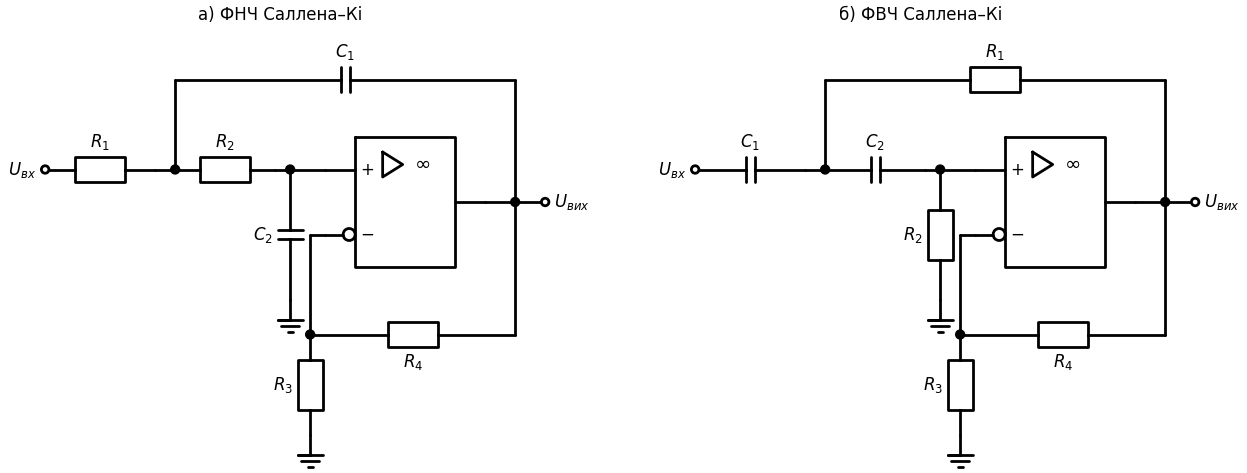

In [2]:
# Ланки Саллена–Кі: а) ФНЧ; б) ФВЧ (резистори і конденсатори поміняно місцями)
if SCHEMDRAW_AVAILABLE:

    def sallen_key(d, ox, kind, title):
        """Ланка Саллена–Кі 2-го порядку (ФНЧ або ФВЧ) з неінвертувальним підсилювачем K = 1 + R4/R3."""
        W = lambda p1, p2: d.add(elm.Line().at((ox + p1[0], p1[1])).to((ox + p2[0], p2[1])))
        ser = (lambda: elm.Resistor(), lambda: elm.Resistor()) if kind == 'lp' else (lambda: elm.Capacitor(), lambda: elm.Capacitor())
        sh = (lambda: elm.Capacitor()) if kind == 'lp' else (lambda: elm.Resistor())
        n1, n2, nf, ns = (('$R_1$', '$R_2$', '$C_1$', '$C_2$') if kind == 'lp' else ('$C_1$', '$C_2$', '$R_1$', '$R_2$'))
        d.add(elm.Label().at((ox + 4.6, 5.0)).label(title))
        o = d.add(OpAmp(swap=True).at((ox + 5.6, 2)).anchor('in2'))
        d.add(elm.Dot(open=True).at((ox, 2)).label('$U_{вх}$', loc='left'))
        d.add(ser[0]().at((ox, 2)).to((ox + 2.2, 2)).label(n1)); W((2.2, 2), (2.6, 2)); d.add(elm.Dot().at((ox + 2.6, 2)))
        d.add(ser[1]().at((ox + 2.6, 2)).to((ox + 4.6, 2)).label(n2)); W((4.6, 2), (5.6, 2)); d.add(elm.Dot().at((ox + 4.9, 2)))
        d.add(sh().at((ox + 4.9, 2)).to((ox + 4.9, -0.6)).label(ns, loc='top')); d.add(elm.Ground().at((ox + 4.9, -0.6)))
        fb = elm.Capacitor if kind == 'lp' else elm.Resistor
        W((2.6, 2), (2.6, 3.8)); d.add(fb().at((ox + 2.6, 3.8)).to((ox + 9.4, 3.8)).label(nf)); W((9.4, 3.8), (9.4, o.out[1]))
        d.add(elm.Line().at(o.out).to((ox + 10.0, o.out[1]))); d.add(elm.Dot().at((ox + 9.4, o.out[1])))
        d.add(elm.Dot(open=True).at((ox + 10.0, o.out[1])).label('$U_{вих}$', loc='right'))
        W((5.6, o.in1[1]), (5.3, o.in1[1])); W((5.3, o.in1[1]), (5.3, -1.3)); d.add(elm.Dot().at((ox + 5.3, -1.3)))
        d.add(elm.Resistor().at((ox + 5.3, -1.3)).to((ox + 5.3, -3.3)).label('$R_3$', loc='top')); d.add(elm.Ground().at((ox + 5.3, -3.3)))
        d.add(elm.Resistor().at((ox + 5.3, -1.3)).to((ox + 9.4, -1.3)).label('$R_4$', loc='bottom')); W((9.4, -1.3), (9.4, o.out[1]))

    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        sallen_key(d, 0, 'lp', 'а) ФНЧ Саллена–Кі')
        sallen_key(d, 13, 'hp', 'б) ФВЧ Саллена–Кі')

---
### 🔬 Інтерактивно: ФНЧ і ФВЧ Саллена–Кі на μA741: вплив K на добротність (PySpice) <a class="anchor" id="sk-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Рівноелементна ланка ($R = 10$ кОм, $C = 10$ нФ, $f_0 = 1{,}59$ кГц) на моделі μA741. Змінюйте коефіцієнт $K = 1 + R_4/R_3$: при $K = 1{,}27$ — Бессель, $1{,}586$ — Баттерворт (−3 дБ точно на $f_0$), $1{,}955$ — Чебишов 1 дБ; ближче до 3 — різкий резонансний пік і самозбудження. Пунктир — теоретична АЧХ ідеальної ланки.

</div>

In [3]:
# Ланка Саллена–Кі (ФНЧ / ФВЧ) на μA741: AC-аналіз і порівняння з теорією
def sallen_key_ac(kind='ФНЧ', K=1.586):
    R, C = 10e3, 10e-9
    c = opamp_circuit('Sallen-Key')
    c.SinusoidalVoltageSource('in', 'in', c.gnd, amplitude=0.1, ac_magnitude=1)
    if kind == 'ФНЧ':
        c.R(1, 'in', 'a', R); c.R(2, 'a', 'p', R); c.C(2, 'p', c.gnd, C); c.C(1, 'a', 'out', C)
    else:
        c.C(1, 'in', 'a', C); c.C(2, 'a', 'p', C); c.R(2, 'p', c.gnd, R); c.R(1, 'a', 'out', R)
    c.R(3, 'm', c.gnd, 10e3); c.R(4, 'out', 'm', max((K - 1) * 10e3, 1e-3))
    add_opamp(c, 1, 'p', 'm', 'out')
    f, v = ac(c, 10, 1e6, 60)
    w0 = 1 / (R * C); Q = 1 / (3 - K) if K < 3 else np.inf
    s = 2j * np.pi * f
    Kt = K * (w0 ** 2 if kind == 'ФНЧ' else s ** 2) / (s ** 2 + s * w0 / Q + w0 ** 2)
    fig, ax = plt.subplots(figsize=(9, 4.2))
    ax.semilogx(f, db(v['out']), color='#F44336', label='μA741 (PySpice)')
    ax.semilogx(f, db(Kt), 'k--', lw=1, label='ідеальна ланка')
    ax.axvline(w0 / 2 / np.pi, color='#2196F3', ls=':', lw=1); ax.axhline(db(K) - 3, color='#FF9800', ls=':', lw=1, label='$K$ − 3 дБ')
    ax.set_ylim(-60, 30); ax.set_xlabel('Частота, Гц'); ax.set_ylabel('дБ'); ax.legend(loc='lower center')
    kindname = {1.27: 'Бессель', 1.586: 'Баттерворт', 1.955: 'Чебишов 1 дБ'}.get(round(K, 3), '')
    ax.set_title(f'{kind} Саллена–Кі: K = {K:.3f}, Q = {Q:.3f} {kindname}')
    plt.tight_layout(); plt.show()
    print(f'f0 = 1/(2πRC) = {w0/2/np.pi:.0f} Гц;  підйом АЧХ ФНЧ на f0 = Q·K = {Q*K:.2f} ({db(Q*K):.1f} дБ)')

interact(sallen_key_ac,
         kind=widgets.ToggleButtons(options=['ФНЧ', 'ФВЧ'], description='Тип'),
         K=widgets.FloatSlider(min=1.0, max=2.9, step=0.001, value=1.586, readout_format='.3f', description='K'));

interactive(children=(ToggleButtons(description='Тип', options=('ФНЧ', 'ФВЧ'), value='ФНЧ'), FloatSlider(value…

---

## Активні ФВЧ на ОП <a class="anchor" id="hpf"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 3.5</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Отримувати ФВЧ із ФНЧ перетворенням $p \to \omega_0^2/p$ (заміною R ↔ C)
> - Розраховувати ФВЧ 1-го і 2-го порядку
> - Знати обмеження ФВЧ на ОП зверху (смуга ОП)

</div>

Схему ФВЧ отримують з ФНЧ **частотним перетворенням** $p \to \omega_0^2/p$, яке схемотехнічно означає **заміну резисторів частотозадавальних кіл конденсаторами і навпаки** (резистори, що задають $K$, не змінюються).

**ФВЧ 1-го порядку:** конденсатор послідовно на вході, резистор до землі:
$$K(p) = K_0\frac{pRC}{1 + pRC},\qquad f_з = \frac{1}{2\pi RC}.$$

**ФВЧ Саллена–Кі 2-го порядку** (схема б вище):
$$K(p) = \frac{K\,p^2}{p^2 + \dfrac{\omega_0}{Q}p + \omega_0^2},\qquad \omega_0 = \frac{1}{\sqrt{R_1R_2C_1C_2}},$$
для рівноелементної ланки знову $\omega_0 = 1/RC$, $Q = 1/(3 - K)$ — ті самі таблиці $K$ для Баттерворта, Чебишова, Бесселя.

**Особливість ФВЧ на ОП:** реальний «ФВЧ» — завжди **смуговий фільтр**: зверху його АЧХ обмежена частотою одиничного підсилення ОП $f_1/K$ (на μA741 з $K = 1{,}586$ — близько 600 кГц), а також швидкістю наростання. Для широкосмугових ФВЧ потрібні швидкі ОП.

**Застосування:** розділення постійної складової і повільного дрейфу (ЕКГ — ФВЧ 0,05…0,5 Гц), придушення низькочастотного гулу і вібрацій, кросовери, виділення ВЧ-складової в системах зв'язку.

---

## Смугові фільтри на ОП <a class="anchor" id="bpf"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 3.6</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Розрізняти широкосмугові (каскад ФВЧ + ФНЧ) і вузькосмугові (резонансні) смугові фільтри
> - Розраховувати смуговий фільтр з багатопетлевим ЗЗ (MFB)
> - Пов'язувати добротність, смугу пропускання і центральну частоту

</div>

**Широкосмуговий СФ** ($f_в/f_н > 2\ldots3$) — каскад ФВЧ (з частотою $f_н$) і ФНЧ (з $f_в$). Кожну ланку розраховують незалежно.

**Вузькосмуговий (резонансний) СФ** — ланка 2-го порядку з передавальною функцією
$$K(p) = \frac{K_0\dfrac{\omega_0}{Q}p}{p^2 + \dfrac{\omega_0}{Q}p + \omega_0^2},\qquad \Delta f = \frac{f_0}{Q},\qquad f_н f_в = f_0^2 .$$

### Смуговий фільтр з багатопетлевим ЗЗ (MFB, Делянніса–Фрейнда)

Вхідний резистор $R_1$, резистор $R_2$ на землю, два конденсатори $C$ — до інвертувального входу і на вихід, резистор $R_3$ у колі ЗЗ:
$$f_0 = \frac{1}{2\pi C}\sqrt{\frac{R_1 + R_2}{R_1R_2R_3}},\qquad Q = \pi f_0R_3C,\qquad K_0 = -\frac{R_3}{2R_1}.$$
Резистор $R_2$ дозволяє незалежно змінювати $f_0$, не змінюючи $Q$ і $K_0$. Обмеження: підсилення ОП на $f_0$ має бути значно більшим за $2Q^2$ — тобто $f_1 \gg 2Q^2f_0$, а для $Q > 10\ldots20$ використовують біквадратні фільтри (зі змінними станами, на 2–3 ОП).

**Застосування:** виділення сигналу на відомій частоті (тональні приймачі DTMF, детектори пілот-сигналів, датчики з модульованим сигналом), еквалайзери і спектроаналізатори (октавні і третинооктавні фільтри), фільтри проміжної частоти НЧ-трактів.

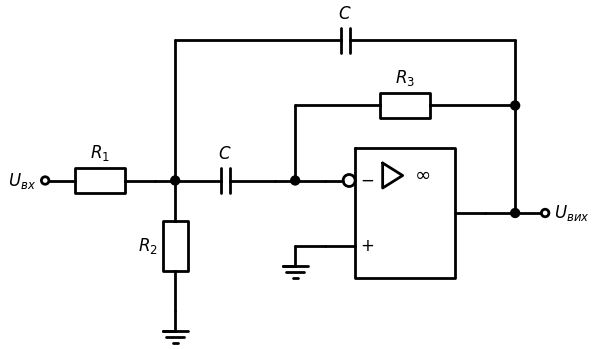

In [4]:
# Смуговий фільтр з багатопетлевим ЗЗ (MFB)
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += (o := OpAmp().at((5.6, 2)).anchor('in1'))
        d += elm.Dot(open=True).at((0, 2)).label('$U_{вх}$', loc='left')
        d += elm.Resistor().at((0, 2)).to((2.2, 2)).label('$R_1$'); d += W((2.2, 2), (2.6, 2)); d += elm.Dot().at((2.6, 2))
        d += elm.Resistor().at((2.6, 2)).to((2.6, -0.6)).label('$R_2$', loc='top'); d += elm.Ground().at((2.6, -0.6))
        d += elm.Capacitor().at((2.6, 2)).to((4.6, 2)).label('$C$'); d += W((4.6, 2), (5.6, 2)); d += elm.Dot().at((5.0, 2))
        d += W((2.6, 2), (2.6, 4.8)); d += elm.Capacitor().at((2.6, 4.8)).to((9.4, 4.8)).label('$C$'); d += W((9.4, 4.8), (9.4, o.out[1]))
        d += W((5.0, 2), (5.0, 3.5)); d += elm.Resistor().at((5.0, 3.5)).to((9.4, 3.5)).label('$R_3$'); d += elm.Dot().at((9.4, 3.5))
        d += elm.Dot().at((9.4, o.out[1])); d += W(o.out, (10.0, o.out[1])); d += elm.Dot(open=True).at((10.0, o.out[1])).label('$U_{вих}$', loc='right')
        d += W(o.in2, (5.0, o.in2[1])); d += elm.Ground().at((5.0, o.in2[1]))

---
### 🔬 Інтерактивно: смуговий фільтр MFB на μA741 (PySpice) <a class="anchor" id="mfb-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Задайте центральну частоту $f_0$ і добротність $Q$ (при $K_0 = -1$, $C = 10$ нФ) — елементи розраховуються за формулами: $R_3 = Q/(\pi f_0C)$, $R_1 = R_3/2$, $R_2 = R_1/(2Q^2 - 1)$. Порівняйте АЧХ на моделі μA741 з ідеальною: при великих $Q f_0$ скінченна смуга ОП зсуває частоту і зменшує добротність.

</div>

In [5]:
# Смуговий фільтр MFB: розрахунок елементів і AC-аналіз на μA741
def mfb(f0=1000.0, Q=5.0):
    C = 10e-9
    R3 = Q / (np.pi * f0 * C); R1 = R3 / 2; R2 = R1 / (2 * Q ** 2 - 1)
    c = opamp_circuit('MFB BPF')
    c.SinusoidalVoltageSource('in', 'in', c.gnd, amplitude=0.1, ac_magnitude=1)
    c.R(1, 'in', 'a', R1); c.R(2, 'a', c.gnd, R2); c.C(1, 'a', 'm', C); c.C(2, 'a', 'out', C); c.R(3, 'm', 'out', R3)
    add_opamp(c, 1, c.gnd, 'm', 'out')
    f, v = ac(c, f0 / 30, f0 * 30, 200)
    s = 2j * np.pi * f; w0 = 2 * np.pi * f0
    Kt = -(w0 / Q) * s / (s ** 2 + s * w0 / Q + w0 ** 2)
    g = np.abs(v['out']); i = np.argmax(g); band = f[g >= g[i] / np.sqrt(2)]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.semilogx(f, db(g), color='#F44336', label=f'μA741: f₀ = {f[i]:.0f} Гц, Q = {f[i]/(band[-1]-band[0]):.2f}')
    ax.semilogx(f, db(Kt), 'k--', lw=1, label=f'ідеальний: f₀ = {f0:.0f} Гц, Q = {Q:.2f}')
    ax.axhline(-3, color='#FF9800', ls=':', lw=1); ax.set_ylim(-40, 5); ax.set_xlabel('Частота, Гц'); ax.set_ylabel('дБ'); ax.legend()
    ax.set_title(f'MFB: R1 = {R1/1e3:.2f} кОм, R2 = {R2:.0f} Ом, R3 = {R3/1e3:.1f} кОм, C = 10 нФ')
    plt.tight_layout(); plt.show()
    print(f'Вимога до ОП: f₁ ≫ 2Q²f₀ = {2*Q**2*f0/1e3:.0f} кГц (у μA741 f₁ ≈ 1000 кГц)')

interact(mfb,
         f0=widgets.FloatLogSlider(base=10, min=2, max=4.3, step=0.05, value=1000, description='f₀ (Гц)'),
         Q=widgets.FloatSlider(min=1, max=20, step=0.5, value=5, description='Q'));

interactive(children=(FloatLogSlider(value=1000.0, description='f₀ (Гц)', max=4.3, min=2.0, step=0.05), FloatS…

---

## Загороджувальні (режекторні) фільтри на ОП <a class="anchor" id="notch"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 3.7</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Знати структури побудови загороджувальних фільтрів
> - Розраховувати активний подвійний Т-міст і фільтр «вхід мінус смуговий»
> - Пояснювати, як ОП підвищує добротність режекторного фільтра

</div>

**Загороджувальний фільтр (ЗФ, режекторний, notch)** пригнічує вузьку смугу частот навколо $f_0$:
$$K(p) = K_0\frac{p^2 + \omega_0^2}{p^2 + \dfrac{\omega_0}{Q}p + \omega_0^2}\qquad(\text{нулі передачі на } \pm j\omega_0).$$

**Можливі структури:**
1. **Паралельне з'єднання ФНЧ і ФВЧ** з підсумовуванням виходів ($f_{ФНЧ} < f_{ФВЧ}$) — для широкої смуги затримування.
2. **«Вхід мінус смуговий фільтр»:** $K_{ЗФ} = 1 - K_{СФ}$. Якщо СФ має $K_0 = 1$ і нульову фазу на $f_0$, сигнал $f_0$ повністю віднімається. Будується на СФ (MFB) і суматорі; добротність ЗФ дорівнює добротності СФ.
3. **Активний подвійний Т-міст:** пасивний twin-T (тема 10) має нуль передачі на $f_0 = 1/2\pi RC$, але низьку добротність $Q = 0{,}25$. Якщо «земляний» вузол моста (точку з'єднання $R/2$ і $2C$) підключити не до землі, а до виходу повторювача, на який подано частину $k$ вихідного сигналу (позитивний ЗЗ — «бутстреп»), добротність зростає:
$$Q = \frac{1}{4(1 - k)},\qquad k = 0{,}9 \Rightarrow Q = 2{,}5;\quad k = 0{,}975 \Rightarrow Q = 10.$$
Глибина режекції визначається точністю елементів моста (1 % — приблизно 40 дБ).
4. **Біквадратні фільтри** (зі змінними станами) — мають окремий режекторний вихід і незалежне налаштування $f_0$, $Q$.

**Застосування:** придушення мережевої завади 50/60 Гц у біомедичних і вимірювальних приладах, вирізання несучої або пілот-тону, придушення акустичного зворотного зв'язку («свисту»), вимірювання коефіцієнта гармонік (режекція основної гармоніки).

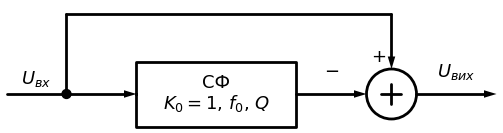

In [6]:
# Структура «вхід мінус смуговий фільтр»
if SCHEMDRAW_AVAILABLE:
    import schemdraw.dsp as dsp
    with schemdraw.Drawing(fontsize=13, unit=1.5) as d:
        d += dsp.Line().at((0, 0)).right(1.2).label('$U_{вх}$', loc='top')
        d += (n := elm.Dot())
        d += dsp.Arrow().right(1.4)
        d += (b := dsp.Box(w=3.2, h=1.3).label('СФ\n$K_0 = 1$, $f_0$, $Q$').anchor('W'))
        d += dsp.Arrow().at(b.E).right(1.4).label('−', loc='top')
        d += (s := dsp.Sum().anchor('W'))
        d += dsp.Arrow().at(s.E).right(1.6).label('$U_{вих}$', loc='top')
        d += dsp.Line().at(n.center).up(1.6)
        d += dsp.Line().right().tox(s.N)
        d += dsp.Arrow().down().toy(s.N)
        d += elm.Label().at((s.N[0] - 0.35, s.N[1] + 0.35)).label('+')

---
### 🔬 Інтерактивно: активний подвійний Т-міст 50 Гц (PySpice) <a class="anchor" id="notch-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Подвійний Т-міст ($R = 31{,}8$ кОм, $C = 100$ нФ, $f_0 = 50$ Гц) з повторювачем на виході (DA1) і бутстрепом «земляного» вузла через другий повторювач (DA2), на який подано частку $k$ вихідної напруги. Збільшуйте $k$ — добротність зростає, смуга режекції звужується; при $k = 0$ — пасивний міст з $Q = 0{,}25$. Розбаланс елементів зменшує глибину режекції.

</div>

In [7]:
# Активний подвійний Т-міст з бутстрепом: AC-аналіз на μA741
def twin_t(k=0.9, mismatch_pct=0.0):
    R, C = 31.83e3, 100e-9
    m = 1 + mismatch_pct / 100
    c = opamp_circuit('active twin-T')
    c.SinusoidalVoltageSource('in', 'in', c.gnd, amplitude=0.1, ac_magnitude=1)
    c.R(1, 'in', 'a', R); c.R(2, 'a', 'p', R); c.C(3, 'a', 'g', 2 * C * m)       # T-ланка R–2C–R
    c.C(1, 'in', 'b', C); c.C(2, 'b', 'p', C); c.R(3, 'b', 'g', R / 2)            # T-ланка C–R/2–C
    add_opamp(c, 1, 'p', 'out', 'out')                                             # DA1 — повторювач
    c.R('k1', 'out', 'kd', (1 - k) * 10e3 + 1e-3); c.R('k2', 'kd', c.gnd, k * 10e3 + 1e-3)
    add_opamp(c, 2, 'kd', 'g', 'g')                                                 # DA2 — повторювач k·U_вих
    f, v = ac(c, 5, 500, 400)
    g = np.abs(v['out'])
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.semilogx(f, db(g), color='#F44336')
    ax.axhline(-3, color='#FF9800', ls=':', lw=1); ax.axvline(50, color='k', ls=':', lw=1)
    lo = f[(f < 50)][np.argmin(abs(db(g[f < 50]) + 3))]; hi = f[(f > 50)][np.argmin(abs(db(g[f > 50]) + 3))]
    ax.set_ylim(-60, 3); ax.set_xlabel('Частота, Гц'); ax.set_ylabel('дБ')
    ax.set_title(f'k = {k:.3f}: смуга режекції (−3 дБ) {lo:.1f}…{hi:.1f} Гц, Q ≈ {50/(hi-lo):.2f} (теорія {1/(4*(1-k)) if k < 1 else np.inf:.2f}); '
                 f'глибина {db(g.min()):.0f} дБ', fontsize=11)
    plt.tight_layout(); plt.show()

interact(twin_t,
         k=widgets.FloatSlider(min=0, max=0.98, step=0.005, value=0.9, readout_format='.3f', description='k'),
         mismatch_pct=widgets.FloatSlider(min=0, max=5, step=0.25, value=0, description='розбаланс (%)'));

interactive(children=(FloatSlider(value=0.9, description='k', max=0.98, readout_format='.3f', step=0.005), Flo…

---

## Фазові (всепропускні) фільтри <a class="anchor" id="allpass"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 3.8</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати призначення фазових фільтрів
> - Виводити передавальну функцію фазового фільтра 1-го порядку на ОП
> - Знати застосування фазових фільтрів

</div>

**Фазовий (всепропускний) фільтр** має $|K(j\omega)| = \text{const}$ на всіх частотах і змінює лише **фазу** (затримку) сигналу. Його нулі дзеркальні полюсам відносно уявної осі.

### Фазовий фільтр 1-го порядку на ОП

ОП з однаковими резисторами $R_1$ у колах інвертувального входу і ЗЗ; на неінвертувальний вхід сигнал подається через RC-коло (конденсатор послідовно, резистор $R$ на землю — або навпаки). За суперпозицією:
$$K(p) = -1 + 2\frac{pRC}{1 + pRC} = -\frac{1 - pRC}{1 + pRC},\qquad |K| = 1,\qquad \varphi(\omega) = 180° - 2\arctan\omega RC .$$
Фаза змінюється від $180°$ (на низьких частотах) до $0°$ (на високих), на $f_0 = 1/2\pi RC$ — рівно $90°$. Якщо поміняти місцями $R$ і $C$ — фаза змінюється від $0°$ до $-180°$. Регулюючи $R$, плавно змінюють фазовий зсув на заданій частоті — **фазообертач**.

**Групова затримка** $t_{гр} = -d\varphi/d\omega = \dfrac{2RC}{1 + (\omega RC)^2}$ — на низьких частотах $\approx 2RC$: фазовий фільтр є **лінією затримки** для низькочастотних сигналів.

**Фазовий фільтр 2-го порядку:** $K(p) = \dfrac{p^2 - p\omega_0/Q + \omega_0^2}{p^2 + p\omega_0/Q + \omega_0^2}$ — фаза $0 \ldots -360°$; будується, наприклад, як «вхід мінус $2\times$СФ».

**Застосування:**
- **фазова корекція** — вирівнювання групової затримки фільтрів (наприклад, Чебишова) у системах передавання даних і відео;
- **фазообертачі і лінії затримки**: однобічна смуга (SSB, метод фазування — пара фазових фільтрів з різницею фаз 90° у широкій смузі), квадратурні генератори, синхронне детектування;
- звукові ефекти (фейзер), кросовери, вирівнювання фаз динаміків;
- вимірювальні мости і схеми зсуву фази синхронізації тиристорних регуляторів.

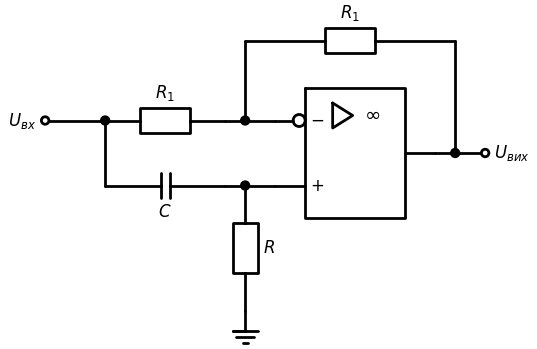

In [8]:
# Фазовий фільтр 1-го порядку на ОП
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += (o := OpAmp().at((4.0, 2)).anchor('in1'))
        d += elm.Dot(open=True).at((-0.6, 2)).label('$U_{вх}$', loc='left'); d += W((-0.6, 2), (0.6, 2)); d += elm.Dot().at((0.6, 2))
        d += elm.Resistor().at((0.6, 2)).to((3.0, 2)).label('$R_1$'); d += W((3.0, 2), (4.0, 2)); d += elm.Dot().at((3.4, 2))
        d += W((3.4, 2), (3.4, 3.6)); d += elm.Resistor().at((3.4, 3.6)).to((7.6, 3.6)).label('$R_1$'); d += W((7.6, 3.6), (7.6, o.out[1]))
        d += elm.Dot().at((7.6, o.out[1])); d += W(o.out, (8.2, o.out[1])); d += elm.Dot(open=True).at((8.2, o.out[1])).label('$U_{вих}$', loc='right')
        d += W((0.6, 2), (0.6, o.in2[1])); d += elm.Capacitor().at((0.6, o.in2[1])).to((3.0, o.in2[1])).label('$C$', loc='bottom')
        d += W((3.0, o.in2[1]), o.in2); d += elm.Dot().at((3.4, o.in2[1]))
        d += elm.Resistor().at((3.4, o.in2[1])).to((3.4, -1.8)).label('$R$', loc='bottom'); d += elm.Ground().at((3.4, -1.8))

---
### 🔬 Інтерактивно: фазообертач на μA741: |K| = 1, фаза регулюється (PySpice) <a class="anchor" id="allpass-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Фазовий фільтр 1-го порядку ($R_1 = 10$ кОм, $C = 100$ нФ) з регульованим $R$. Ліворуч — АЧХ і ФЧХ (амплітуда стала, фаза $180° - 2\arctan\omega RC$), праворуч — вхідна і вихідна синусоїди частотою 500 Гц: амплітуда однакова, змінюється лише зсув.

</div>

In [9]:
# Фазовий фільтр 1-го порядку на μA741: АЧХ/ФЧХ і часові діаграми
def allpass(R_k=3.2, f_sig=500.0):
    R, C = R_k * 1e3, 100e-9
    def build():
        c = opamp_circuit('all-pass')
        c.SinusoidalVoltageSource('in', 'in', c.gnd, amplitude=1, frequency=f_sig, ac_magnitude=1)
        c.R(1, 'in', 'm', 10e3); c.R(2, 'm', 'out', 10e3); c.C(1, 'in', 'p', C); c.R(3, 'p', c.gnd, R)
        add_opamp(c, 1, 'p', 'm', 'out')
        return c
    f, v = ac(build(), 10, 1e5, 40)
    t, vt = tran(build(), 2e-6, 4 / f_sig, start=2 / f_sig)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
    a1.semilogx(f, db(v['out']), color='#2196F3', label='|K|, дБ'); a1.set_ylim(-10, 5); a1.set_ylabel('|K|, дБ', color='#2196F3')
    b = a1.twinx(); b.semilogx(f, np.degrees(np.angle(v['out'])), color='#F44336'); b.set_ylabel('φ, град', color='#F44336'); b.set_ylim(-10, 190)
    f0 = 1 / (2 * np.pi * R * C); a1.axvline(f0, color='k', ls=':', lw=1); a1.axvline(f_sig, color='#4CAF50', ls=':', lw=1)
    a1.set_xlabel('Частота, Гц'); a1.set_title(f'f₀ = 1/(2πRC) = {f0:.0f} Гц (φ = 90°)')
    tt = (t - t[0]) * 1e3
    a2.plot(tt, vt['in'], 'k--', lw=1, label='$u_{вх}$'); a2.plot(tt, vt['out'], color='#F44336', label='$u_{вих}$')
    phi = 180 - 2 * np.degrees(np.arctan(2 * np.pi * f_sig * R * C))
    a2.set_xlabel('t, мс'); a2.legend(loc='upper right'); a2.set_title(f'{f_sig:.0f} Гц: теоретичний зсув {phi:.1f}°')
    plt.tight_layout(); plt.show()

interact(allpass,
         R_k=widgets.FloatSlider(min=0.2, max=50, step=0.1, value=3.2, description='R (кОм)'),
         f_sig=widgets.FloatSlider(min=100, max=2000, step=50, value=500, description='f сигналу (Гц)'));

interactive(children=(FloatSlider(value=3.2, description='R (кОм)', max=50.0, min=0.2), FloatSlider(value=500.…

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**Високодобротна ланка на ОП вимагає «запасу» підсилення ОП.** Формули ланок виведено для ідеального ОП. Реально ОП повинен мати на частоті $f_0$ підсилення в десятки разів більше за потрібне ланці: для MFB-фільтра — $f_1 \gg 2Q^2f_0$, для Саллена–Кі — $f_1 \gg K Q f_0$. Інакше центральна частота і добротність «пливуть» (див. моделювання MFB з великим $Q$ на μA741).

</div>

---
### ⚡ Практичне застосування: активні фільтри на ОП

<div style="background-color: #fffbeb; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #f59e0b; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Застосування | Фільтр |
|---|---|
| Антиелайзинговий фільтр перед АЦП (звук 44,1 кГц) | ФНЧ Баттерворта/еліптичний 4–8 порядку, ланки Саллена–Кі або MFB |
| Згладжування ШІМ-ЦАП мікроконтролера | ФНЧ Саллена–Кі 2–4 порядку |
| ЕКГ-підсилювач | ФВЧ 0,05 Гц + ФНЧ 150 Гц + режекторний 50 Гц |
| Тональний декодер, виділення пілот-сигналу | вузькосмуговий MFB або біквадратний СФ |
| Вимірювач коефіцієнта гармонік | режекторний фільтр основної частоти |
| SSB-модулятор фазовим методом, квадратурні сигнали | пара фазових фільтрів з різницею 90° |
| Еквалайзер | набір смугових фільтрів + суматор |

</div>

---
### ✅ Питання для самоперевірки: активні фільтри на ОП

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Як у рівноелементній ланці Саллена–Кі задається тип АЧХ?</summary>

> **Відповідь:** Коефіцієнтом підсилення $K = 1 + R_4/R_3$: $Q = 1/(3-K)$; Баттерворт — $K = 1{,}586$, Бессель — 1,27, Чебишов 1 дБ — 1,955.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Як із ФНЧ отримати ФВЧ?</summary>

> **Відповідь:** Замінити резистори частотозадавальних кіл конденсаторами і навпаки (перетворення $p \to \omega_0^2/p$).

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Як розрахувати центральну частоту і добротність MFB-фільтра?</summary>

> **Відповідь:** $f_0 = \frac{1}{2\pi C}\sqrt{\frac{R_1+R_2}{R_1R_2R_3}}$, $Q = \pi f_0R_3C$, $K_0 = -R_3/2R_1$.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Як ОП підвищує добротність подвійного Т-моста?</summary>

> **Відповідь:** Бутстреп «земляного» вузла моста частиною $k$ вихідної напруги через повторювач: $Q = 1/4(1-k)$.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Що змінює фазовий фільтр?</summary>

> **Відповідь:** Лише фазу (групову затримку) сигналу; амплітуда стала на всіх частотах.

</details>

---
### 📝 Задачі для самостійного розв'язання: активні фільтри на ОП


<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 1.** Розрахуйте рівноелементний ФНЧ Баттерворта Саллена–Кі на 2 кГц з $C = 10$ нФ, $R_3 = 10$ кОм.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $R = 1/(2\pi\cdot2000\cdot10^{-8}) = 7{,}96$ кОм; $K = 1{,}586 \Rightarrow R_4 = 5{,}86$ кОм; підсилення в СП 4 дБ.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 2.** MFB-фільтр: $f_0 = 1$ кГц, $Q = 10$, $K_0 = -1$, $C = 10$ нФ. Знайдіть $R_1$, $R_2$, $R_3$ і вимогу до $f_1$ ОП.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $R_3 = Q/(\pi f_0C) = 318$ кОм; $R_1 = 159$ кОм; $R_2 = R_1/(2Q^2-1) = 799$ Ом; $f_1 \gg 2Q^2f_0 = 200$ кГц — μA741 на межі, краще ОП з $f_1 \ge 10$ МГц.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 3.** Фазообертач 1-го порядку з $C = 100$ нФ має давати зсув $90°$ на 50 Гц. Знайдіть $R$ і групову затримку на низьких частотах.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $R = 1/(2\pi\cdot50\cdot10^{-7}) = 31{,}8$ кОм; $t_{гр} \approx 2RC = 6{,}4$ мс.

</details>

---

### 📌 Підсумок теми <a class="anchor" id="topic-summary"></a>

<div style="background-color: #f0fdf4; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #16a34a; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Фільтр | Співвідношення |
|---|---|
| ФНЧ/ФВЧ 1-го порядку | $f_з = 1/2\pi RC$, 20 дБ/дек |
| Саллен–Кі (рівноелементна) | $\omega_0 = 1/RC$, $Q = 1/(3 - K)$; Баттерворт $K = 1{,}586$ |
| MFB смуговий | $f_0 = \frac{1}{2\pi C}\sqrt{\frac{R_1+R_2}{R_1R_2R_3}}$, $Q = \pi f_0R_3C$, $K_0 = -R_3/2R_1$ |
| Активний twin-T | $f_0 = 1/2\pi RC$, $Q = 1/4(1 - k)$ |
| Режекторний «вхід − СФ» | $K_{ЗФ} = 1 - K_{СФ}$ |
| Фазовий 1-го порядку | $|K| = 1$, $\varphi = 180° - 2\arctan\omega RC$, $t_{гр}(0) = 2RC$ |

**Головні висновки.** Ланки 2-го порядку на одному ОП (Саллена–Кі, MFB) — основа практичних фільтрів: ФНЧ і ФВЧ отримують взаємною заміною R і C, смуговий — резонансною ланкою, загороджувальний — нулем передачі (twin-T або відніманням СФ), фазовий — дзеркальними нулями. Обмеження — смуга і швидкість наростання ОП, чутливість високодобротних ланок до розкиду елементів.

</div>

---

## 📚 Рекомендована література та ресурси <a class="anchor" id="references"></a>

**Основна література**

1. Гусев В. Г., Гусев Ю. М. Електроніка і мікропроцесорна техніка. — К.: Вища школа (укр. пер.).
2. Опадчий Ю. Ф., Глудкин О. П., Гуров А. И. Аналоговая и цифровая электроника. — М.: Горячая линия – Телеком, 2000.
3. Титце У., Шенк К. Полупроводниковая схемотехника. — 12-е изд. — М.: ДМК Пресс, 2008.
4. Хоровиц П., Хилл У. Искусство схемотехники. — М.: Мир / Horowitz P., Hill W. The Art of Electronics. — 3rd ed. — Cambridge University Press, 2015.
5. Sedra A. S., Smith K. C. Microelectronic Circuits. — 8th ed. — Oxford University Press, 2020.

**Додаткова література**

6. Texas Instruments. Active Filter Design Techniques / Op Amps for Everyone, ch. 16 (SLOA088).
7. Huelsman L. P. Active and Passive Analog Filter Design. — McGraw-Hill, 1993.

**Програмні інструменти, що використовуються в конспекті**

- [PySpice](https://pyspice.fabrice-salvaire.fr/) + [ngspice](https://ngspice.sourceforge.io/) — схемотехнічне моделювання
- [SchemDraw](https://schemdraw.readthedocs.io/) — побудова електричних схем
- [SymPy](https://docs.sympy.org/) — символьні обчислення
- [NumPy](https://numpy.org/doc/) / [SciPy](https://docs.scipy.org/doc/scipy/) / [Matplotlib](https://matplotlib.org/) — чисельні розрахунки та графіки

---

<p style="text-align: center;">⬅️ [Тема 10. Активні фільтри: класифікація, поліноми, елементарні ланки](Тема_10_Активні_фільтри_основи.ipynb) &nbsp;|&nbsp; [Тема 12. Генератори гармонійних коливань](Тема_12_Генератори_гармонійних_коливань.ipynb) ➡️</p>

*Конспект підготовлено: Пахалюк Богдан Петрович, НУ "Чернігівська політехніка"*